# Aufgabe 4: Gammakorrektur
Die Grauwerttransformation
\begin{equation*}
 f_2(x,y) = f_1(x,y)^\gamma, \qquad \text{mit } \underset{(x,y)\in \Omega}{\forall}: f_1(x, y) \in \left[0,1\right]
\end{equation*}
wird auch als *Gammakorrektur* bezeichnet.

Implementieren sie eine Python-Funktion, welche diese Operation mit variablem Parameter $\gamma$ realisiert!
Welchen Einfluss hat dieser Parameter $\gamma$? Wie wird das Bild bei $\gamma=2.5$ verändert, wie bei $\gamma=0.5$?
Wofür könnte eine solche Gammakorrektur jeweils verwendet werden?

## 0. Pfade, Pakete etc.

In [1]:
import glob
import urllib.request

%matplotlib inline
import matplotlib.pyplot as plt

import imageio
import numpy as np

In [2]:
image_filter = 'Bilder/*.jpg'

## 1. Parameter $\gamma$
Hier wird $\gamma$ definiert, um den Korrekturprozess einfach zu beeinlussen:

In [3]:
gamma = 0.5

## 2. Laden des Bildes
Laden Sie ein zufälliges Bild aus dem Materialordner in `image`:

In [4]:
image = imageio.v3.imread(np.random.choice(glob.glob(image_filter)), mode='L')

## 3. Normalisieren des Bildes
Setzen Sie hier ihre Lösung aus der vorherigen Teilaufgabe ein, um die Grauwerte von `image` zu normieren. Achten Sie darauf, einen angemessenen Datentypen zu verwenden!

In [5]:
image = image.astype(np.float64)
image = (image - image.min()) / (image.max() - image.min())

## 4. Gammakorrektur
Definieren Sie eine Funktion `ex1_gammacorrect`, die ein gammakorrigiertes Bild für ein gegebenes Bild und einen Parameter $\gamma$ zurückgibt.

In [6]:
def ex1_gammacorrect(image, gamma):
    return image ** gamma

## 5. Darstellen des Bildes

Die Gammakorrektur wird nun ausgeführt:

In [7]:
image_corrected = ex1_gammacorrect(image, gamma=gamma)

Stellen Sie das Originalbild und das gammakorrigierte Bild nebeneinander dar:

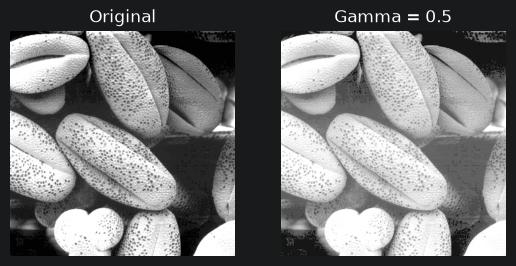

In [8]:
plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=1)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(image_corrected, cmap='gray', vmin=0, vmax=1)
plt.title(f'Gamma = {gamma}')
plt.axis('off')

plt.show()

**Einfluss von $\gamma$:** Da $f_1 \in [0,1]$, bleiben 0 und 1 fest, nur die Werte dazwischen werden verschoben.
- $\gamma > 1$ (z. B. $2.5$): Das Bild wird dunkler, dunkle Bereiche werden stark zusammengedrückt, helle Bereiche gespreizt. Nützlich für überbelichtete Bilder bzw. um Details in hellen Bereichen sichtbar zu machen.
- $\gamma < 1$ (z. B. $0.5$): Das Bild wird heller, dunkle Bereiche werden gespreizt. Nützlich für unterbelichtete Bilder bzw. um Details in Schatten sichtbar zu machen.
- $\gamma = 1$: keine Änderung.